# E-commerce Delivery Performance & Customer Experience Analysis

**Product question.** Where should marketplace operations investigate promise misses, and how do those misses coincide with customer ratings?

This case study uses historical Brazilian marketplace orders published by Olist. See the [data setup](../data/README.md), [methodology](../README.md) and [executive summary](../report/executive_summary.md).

## Run the analysis

The same pipeline powers this notebook and the command-line entry point. It validates the source keys, builds one row per order, and compares its Pandas aggregates with executed SQL before writing the outputs.

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis.py").is_file())
src = str(root / "src")
if src not in sys.path:
    sys.path.insert(0, src)
from analysis import run

metrics, tables, quality = run()
print(f"Purchase window: {quality['purchase_start']} to {quality['purchase_end']}")
print(f"SQL cross-checks passed: {len(quality['sql_cross_checks_passed'])}")

Purchase window: 2016-09-04 to 2018-10-17
SQL cross-checks passed: 7


## Source quality and order grain

Source keys and join cardinalities are checked before aggregation. Multiple valid review records resolve to the latest answer per order. Items are reduced to distinct orderÃ¢â‚¬â€œseller and orderÃ¢â‚¬â€œcategory pairs. The marketplace totals always come from the order fact.

In [2]:
source_quality = pd.DataFrame([
    {"source": name, "rows": s["rows"], "exact duplicates removed": s["exact_duplicates_removed"],
     "fields with missing values": len(s["missing_by_column"])}
    for name, s in quality["sources"].items()
])
display(source_quality)
print(f"Delivered rows missing required dates: {quality['delivered_missing_required_dates']}")
print(f"Delivered rows with an invalid date sequence: {quality['delivered_invalid_date_order']}")
print(f"Additional valid review rows removed: {quality['additional_valid_review_rows_removed']}")
print(f"Orders without a valid review: {quality['orders_without_valid_review']:,}")

,source,rows,exact duplicates removed,fields with missing values
0,olist_orders_dataset.csv,99441,0,3
1,olist_order_items_dataset.csv,112650,0,0
2,olist_customers_dataset.csv,99441,0,0
3,olist_sellers_dataset.csv,3095,0,0
4,olist_products_dataset.csv,32951,0,8
5,olist_order_reviews_dataset.csv,99224,0,2
6,product_category_name_translation.csv,71,0,0


Delivered rows missing required dates: 8
Delivered rows with an invalid date sequence: 0
Additional valid review rows removed: 551
Orders without a valid review: 768


## Delivery reliability

Delivery duration is actual delivery minus purchase. Signed delay is actual delivery minus the stored estimate. A positive difference is late. Timing uses delivery-status rows with a valid purchase, estimated and actual timestamp. The date-only sensitivity checks the effect of treating delivery on the estimated calendar day as on time.

In [3]:
display(tables["kpi_summary"].round(2))
display(tables["delay_distribution"].round(2))

,metric,value
0,total_orders,99441.00
1,delivered_orders,96478.00
2,canceled_orders,625.00
3,unavailable_orders,609.00
4,eligible_orders,96470.00
5,on_time_orders,88644.00
6,late_orders,7826.00
7,on_time_pct,91.89
8,late_pct,8.11
9,mean_delivery_days,12.56


,delay_days_bucket,orders,order_pct
0,≤−14,34939,36.22
1,−14 to −7,36364,37.69
2,−7 to 0,17341,17.98
3,0 to 3,2662,2.76
4,3 to 7,1819,1.89
5,7 to 14,1790,1.86
6,>14,1555,1.61


## Customer experience

A low rating is one or two stars. Each comparison uses only eligible orders with a valid review. The association can reflect differences in seller, product, geography, time period or who leaves a review.

In [4]:
display(tables["review_score_distribution"].round(2))
display(tables["review_by_timing"].round(2))
display(tables["review_by_delay"].round(2))
print(f"Pearson correlation for signed delay and review score: {quality['pearson_delay_vs_review']:.3f}")

,review_score,reviewed_orders,review_pct
0,1,11363,11.52
1,2,3131,3.17
2,3,8133,8.24
3,4,19038,19.29
4,5,57008,57.77


,timing,reviewed_orders,mean_review_score,low_review_orders,low_review_pct
0,Late,7661,2.57,4142,54.07
1,On time,88163,4.29,8130,9.22


,timing,reviewed_orders,mean_review_score,low_review_orders,low_review_pct
0,On time,88163,4.29,8130,9.22
1,>0–3 days late,2636,3.77,504,19.12
2,>3–7 days late,1773,2.32,1087,61.31
3,>7–14 days late,1748,1.74,1366,78.15
4,>14 days late,1504,1.71,1185,78.79


Pearson correlation for signed delay and review score: -0.267


## Fulfilment segments and a candidate early-warning signal

Rates use at least 500 eligible orders per category or customer state and at least 100 per seller. Sellers marked as repeatedly above benchmark had at least 25 orders in each of the 2017 and 2018 observation windows and exceeded the corresponding marketplace late rate in both. Review case volume as well as rate when choosing where to investigate.

In [5]:
segment_metrics = ["orders", "late_orders", "late_pct", "mean_review_score"]
display(tables["category_performance"][["category", *segment_metrics]].head(8).round(2))
display(tables["seller_performance"].loc[
    lambda df: df["above_benchmark_both_years"],
    ["seller_id", *segment_metrics, "late_pct_2017", "late_pct_2018"],
].head(6).round(2))
display(tables["state_performance"][["customer_state", *segment_metrics]].round(2))
display(tables["handoff_performance"][["handoff_group", *segment_metrics]].round(2))

,category,orders,late_orders,late_pct,mean_review_score
0,electronics,2517,247,9.81,4.12
1,baby,2809,258,9.18,4.10
2,office_furniture,1254,115,9.17,3.64
3,unknown,1392,127,9.12,4.01
4,construction_tools_construction,736,67,9.10,4.13
5,health_beauty,8647,775,8.96,4.23
6,musical_instruments,611,54,8.84,4.23
7,bed_bath_table,9272,811,8.75,4.00


,seller_id,orders,late_orders,late_pct,mean_review_score,late_pct_2017,late_pct_2018
1,1ca7077d890b907f89be8c954a02686a,108,24,22.22,2.39,17.31,26.79
3,e5a3438891c0bfdb9394643f95273d8e,216,40,18.52,3.99,16.22,20.95
4,cd68562d3f44870c08922d380acae552,122,22,18.03,4.02,15.62,26.92
5,8160255418d5aaa7dbdc9f4c64ebda44,380,63,16.58,3.95,29.46,11.19
6,2c9e548be18521d1c43cde1c582c6de8,124,20,16.13,4.13,11.11,17.53
7,dd7ddc04e1b6c2c614352b383efe2d36,121,19,15.70,3.88,16.95,14.52


,customer_state,orders,late_orders,late_pct,mean_review_score
0,MA,717,141,19.67,3.83
1,CE,1279,196,15.32,3.94
2,BA,3256,457,14.04,3.93
3,RJ,12350,1664,13.47,3.97
4,PA,946,117,12.37,3.91
5,ES,1995,244,12.23,4.08
6,MS,701,81,11.55,4.16
7,PB,517,57,11.03,4.08
8,PE,1593,172,10.80,4.08
9,SC,3546,346,9.76,4.13


,handoff_group,orders,late_orders,late_pct,mean_review_score
0,Over 3 days,30318,3923,12.94,3.97
1,Within 3 days,64764,3869,5.97,4.24


## Dashboard

Dashed reference lines mark the marketplace late rate. Seller IDs in the chart are abbreviated. The [full seller table](../outputs/seller_performance.csv) contains the original IDs and the year-level rates.

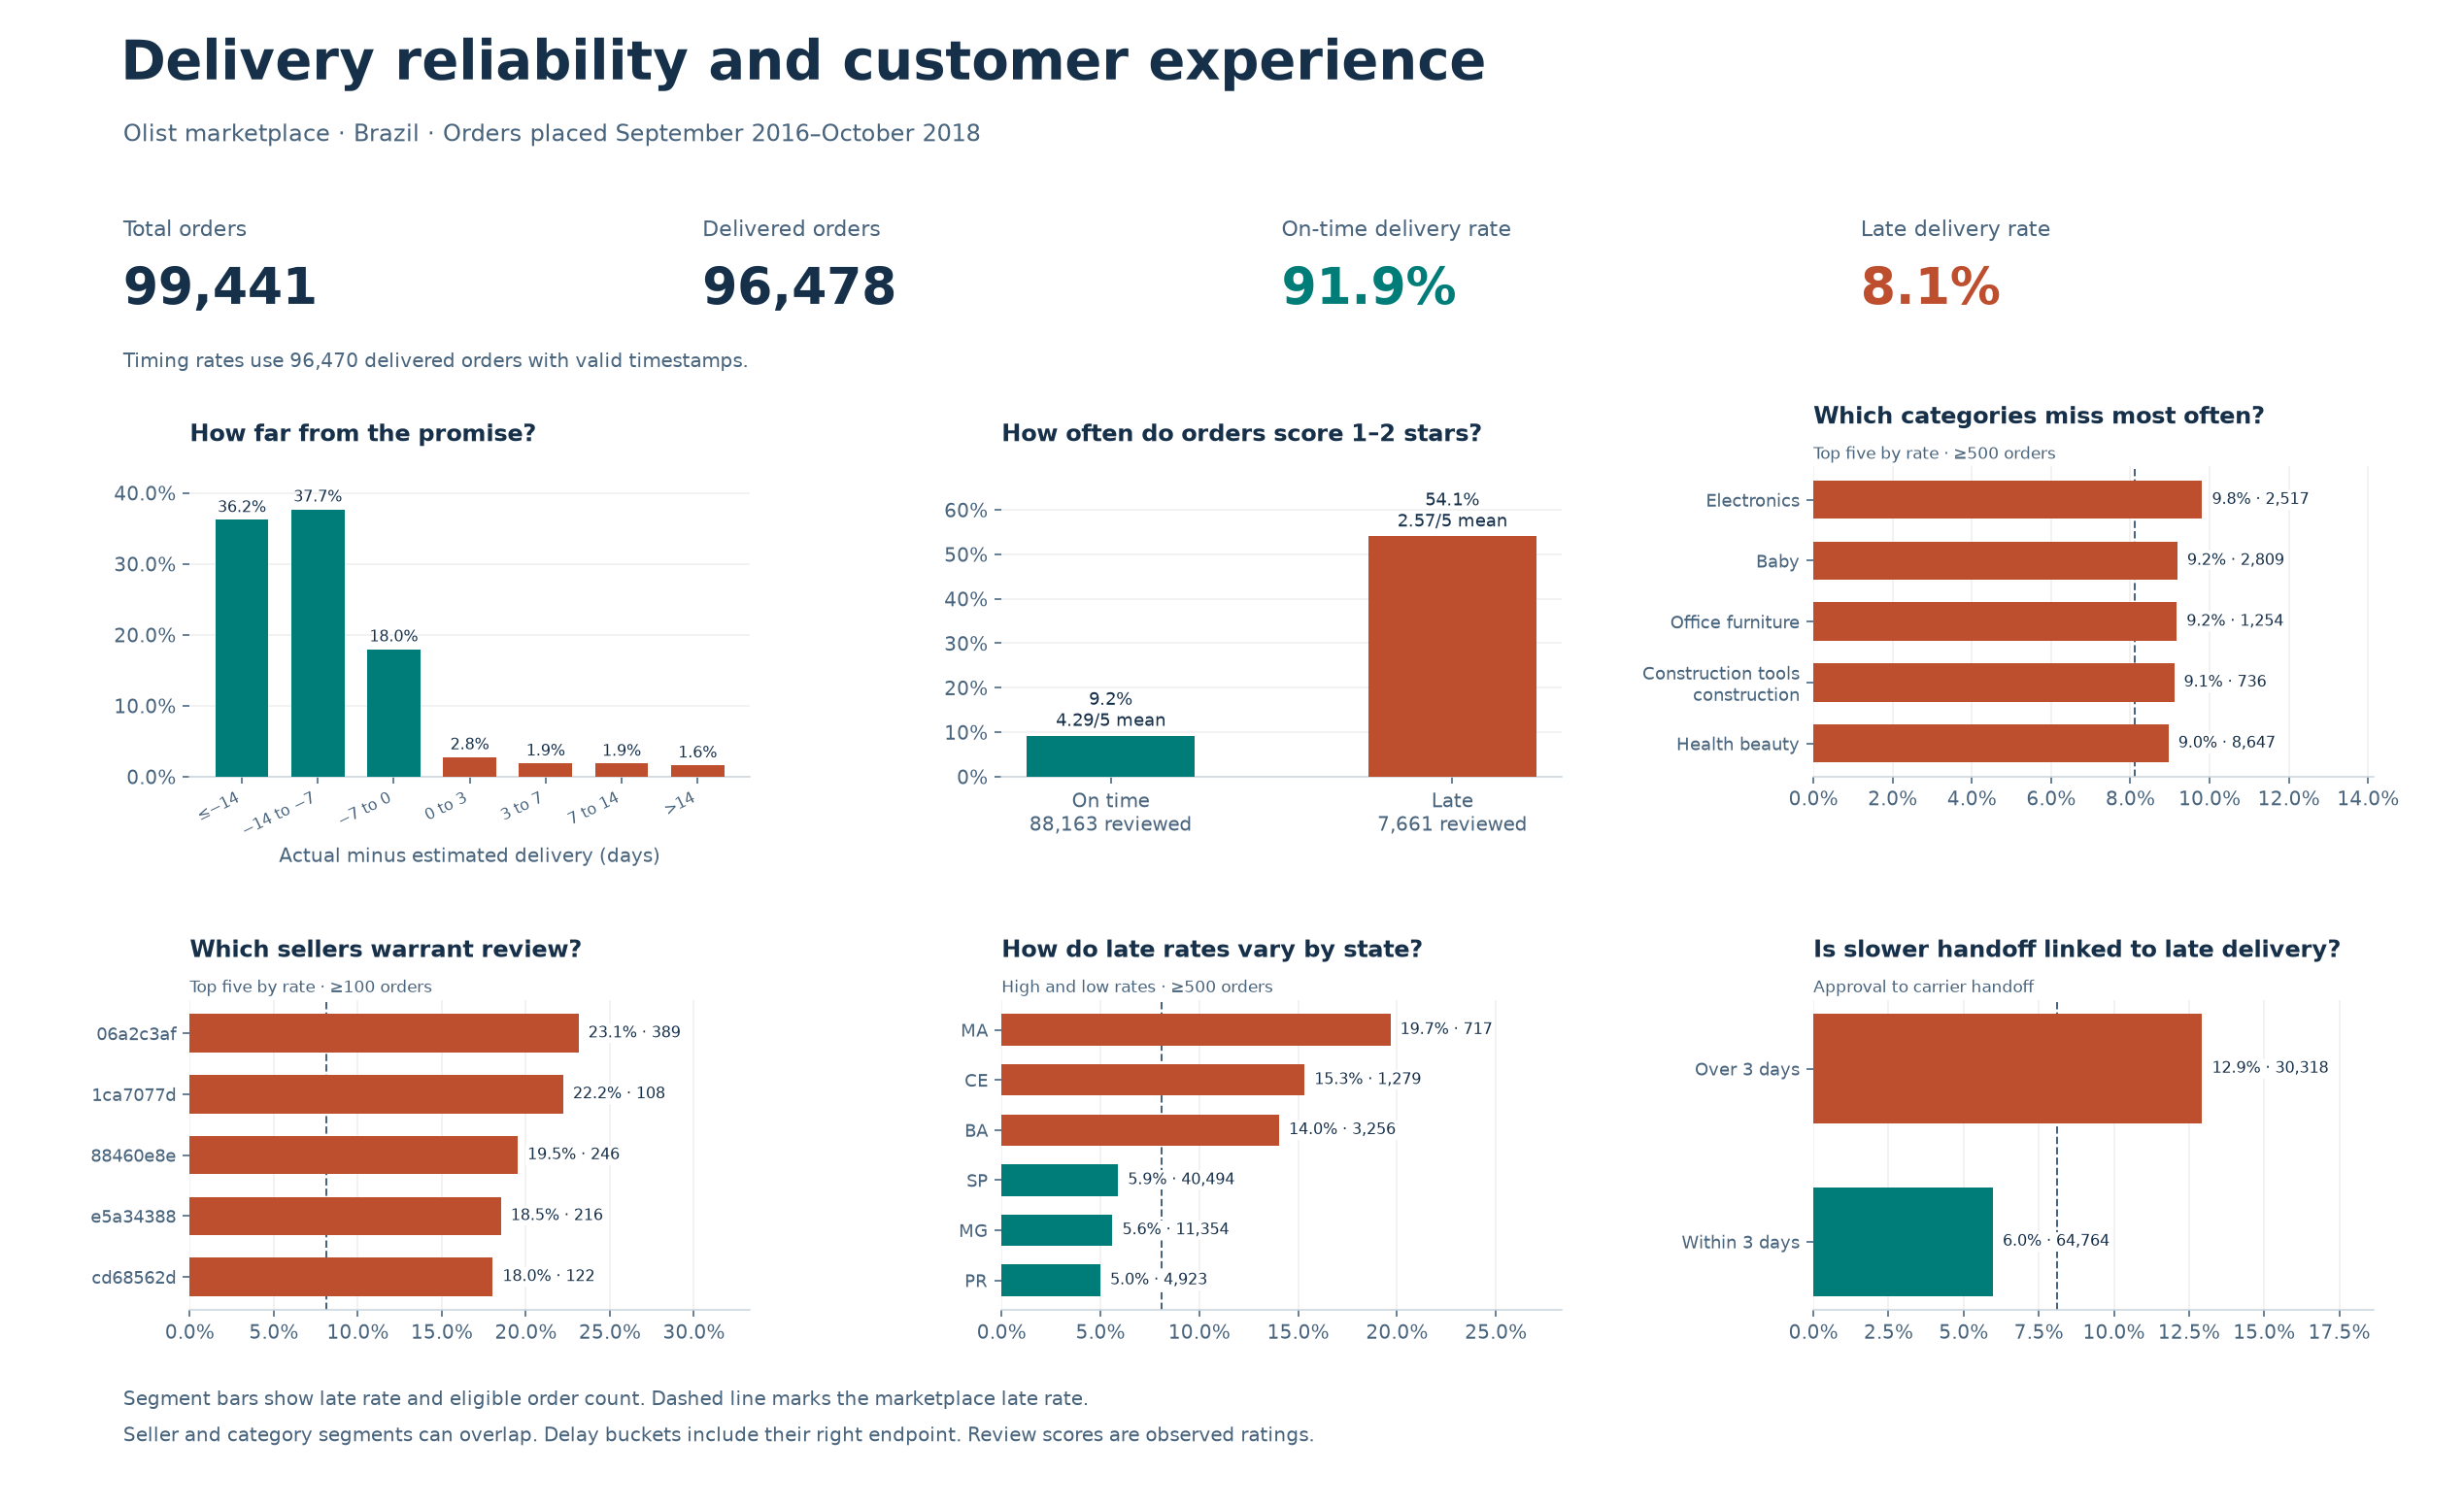

In [6]:
display(Image(filename=str(root / "outputs" / "charts" / "delivery_dashboard.png"), width=1150))